# 00 · Inicio: entorno, mercados, baselines y protocolo

> **Notebook de entrada al proyecto.** Explica el problema, valida el código común de `src/`, mide los
> baselines y **cierra las decisiones comunes** que usan el resto de notebooks:
> el protocolo de train/test (**D-0.1**) y la discretización del estado (**D-1.1**).

| § | Contenido | Qué sale de aquí |
|---|---|---|
| 0 | Mapa del proyecto | Cómo encaja cada pieza |
| 1 | El problema, paso a paso | Estado, acciones y recompensa con datos reales |
| 2 | Los cuatro mercados | Qué estrategia cabe esperar en cada uno |
| 3 | Un episodio de ejemplo | El entorno funciona como en el taller |
| 4 | La tendencia y su discretización | Bins por mercado (D-1.1) |
| 5 | Protocolo de train/test | Semillas y número de series de test (D-0.1) |
| 6 | Baselines: aleatorio y buy & hold | `results/00_baselines.csv`, el listón a batir |
| 7 | Calibración con un Q-Learning rápido | α adecuado y número de bins por defecto (D-1.1) |
| 8 | Decisiones cerradas y cómo seguir | Plantilla para 01, 02 y 03 |

Teoría de referencia: [`docs/teoria/notebook_partida.md`](../docs/teoria/notebook_partida.md) (empezad por ahí) y
[`docs/teoria/02_td_sarsa_qlearning.md`](../docs/teoria/02_td_sarsa_qlearning.md).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

from src.env import SimpleTradingEnv, discretize, n_states, TREND_EDGES
from src.markets import MARKETS, make_prices
from src.agents import RandomAgent, BuyHoldAgent, QLearningAgent, SarsaAgent
from src.experiment import (train, evaluate, run_episode, summarize, save_results,
                            quantile_edges, plot_episode, plot_learning_curve, RESULTS_DIR,
                            N_STEPS, N_TEST, N_BINS, TEST_SEED_OFFSET)
from src.style import setup, savefig, AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, POSITION_COLORS

setup()
pd.set_option("display.precision", 3)
print(f"Series de {N_STEPS} pasos · {N_TEST} series de test (semillas desde {TEST_SEED_OFFSET:,})")

Series de 500 pasos · 200 series de test (semillas desde 100,000)


## 0. Mapa del proyecto

Todo el código común vive en `src/` y es la **única fuente de verdad**. Cada notebook es una línea de trabajo
independiente que escribe sus resultados en `results/` con el mismo esquema de columnas, y el 04 solo junta esos
CSV para el informe. Así tres personas pueden trabajar a la vez sin pisarse.

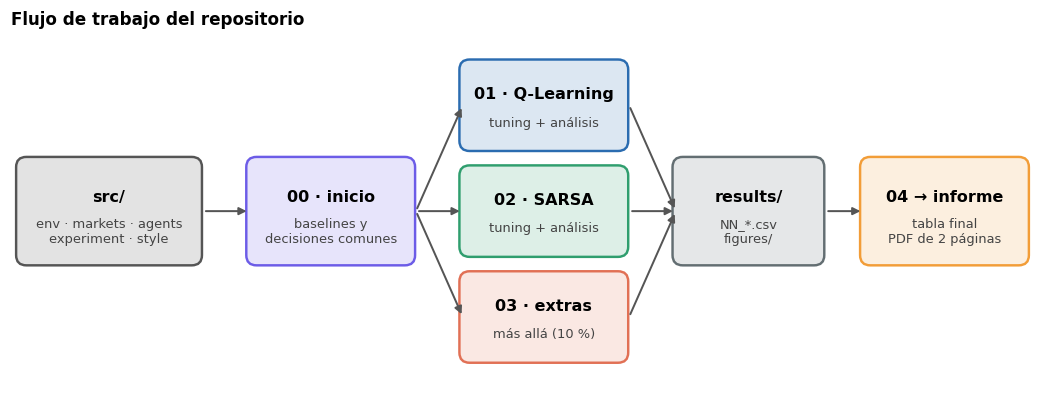

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.2); ax.axis("off")

def box(x, y, w, h, title, sub, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=color, ec="none", alpha=0.16))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc="none", ec=color, lw=1.6))
    ax.text(x + w / 2, y + h * 0.64, title, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, y + h * 0.30, sub, ha="center", va="center", fontsize=8.5, color="#444")

def arrow(x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.3))

box(0.1, 1.5, 2.1, 1.2, "src/", "env · markets · agents\nexperiment · style", "#555555")
box(2.8, 1.5, 1.9, 1.2, "00 · inicio", "baselines y\ndecisiones comunes", "#6C5CE7")
box(5.3, 2.85, 1.9, 1.0, "01 · Q-Learning", "tuning + análisis", AGENT_COLORS["qlearning"])
box(5.3, 1.6, 1.9, 1.0, "02 · SARSA", "tuning + análisis", AGENT_COLORS["sarsa"])
box(5.3, 0.35, 1.9, 1.0, "03 · extras", "más allá (10 %)", "#E17055")
box(7.8, 1.5, 1.7, 1.2, "results/", "NN_*.csv\nfigures/", "#636E72")
box(10.0, 1.5, 1.9, 1.2, "04 → informe", "tabla final\nPDF de 2 páginas", "#F29D38")
arrow(2.25, 2.1, 2.8, 2.1)
for y in (3.35, 2.1, 0.85):
    arrow(4.75, 2.1, 5.3, y); arrow(7.25, y, 7.8, 2.1)
arrow(9.55, 2.1, 10.0, 2.1)
ax.set_title("Flujo de trabajo del repositorio", loc="left")
savefig(fig, "00_mapa_proyecto"); plt.show()

## 1. El problema, paso a paso

El agente opera **un único activo** con 1 000 $ iniciales. En cada paso ve un estado y elige una acción:

| | Definición (código del taller, `src/env.py`) |
|---|---|
| **Observación** | `(tendencia, posición)`. La tendencia es $\dfrac{p_t - \overline{p}_{t-5:t}}{\overline{p}_{t-5:t}}$ (desviación del precio frente a la media de los 6 últimos), recortada a $[-1, 1]$. La posición es 1 si tiene el activo y 0 si no |
| **Acciones** | `0` vender · `1` mantener · `2` comprar. Vender sin activo o comprar con él no hace nada |
| **Ejecución** | Todo el capital, al último precio observado $p_t$ (sin mirar al futuro), con comisión del 0,1 % |
| **Recompensa** | $r_t = \underbrace{-0{,}001}_{\text{si opera}} + \underbrace{\tfrac{p_{t+1}-p_t}{p_t}}_{\text{si acaba el paso con el activo}}$ |
| **Episodio** | Empieza en el paso 5 sin activo y acaba con la serie: 494 decisiones con $n = 500$ |

La tendencia es **continua**, así que para los métodos tabulares `discretize()` la convierte en un **bin**, y el
estado discreto es `bin × 2 + posición`. La tabla de abajo es un tramo real de un episodio con un agente
aleatorio: cada fila es una decisión.

In [3]:
prices = make_prices("regimenes", N_STEPS, seed=3)
env = SimpleTradingEnv(prices)
agent = RandomAgent(seed=1)
obs, _ = env.reset()
rows = []
for _ in range(10):
    t, trend, pos = env.current_step, float(obs[0]), env.position
    s = discretize(obs)
    a = agent.act(s)
    obs, r, done, _, info = env.step(a)
    rows.append({"paso": t, "precio": prices[t], "tendencia": trend, "posición": pos, "estado": s,
                 "acción": ["vender", "mantener", "comprar"][a], "recompensa": r, "balance": info["balance"]})
tabla = pd.DataFrame(rows).set_index("paso")
display(tabla.style.format({"precio": "{:.2f}", "tendencia": "{:+.4f}", "recompensa": "{:+.5f}", "balance": "{:,.2f}"})
        .background_gradient(subset=["recompensa"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)
        .map(lambda v: "color:#2F9E6E;font-weight:bold" if v == "comprar" else
                       ("color:#D63031;font-weight:bold" if v == "vender" else "color:#888"), subset=["acción"]))
print(f"Estados discretos del proyecto: {n_states(quantile_edges('regimenes', N_BINS))} "
      f"({N_BINS} bins de tendencia x 2 posiciones, D-1.1). La tabla usa los 5 bins fijos solo como ejemplo.")

,precio,tendencia,posición,estado,acción,recompensa,balance
paso,,,,,,,
5,99.81,-0.0013,0,4,mantener,+0.00000,"1,000.00"
6,98.29,-0.0153,0,2,mantener,+0.00000,"1,000.00"
7,98.78,-0.0080,0,2,comprar,-0.00561,994.40
8,98.32,-0.0101,1,3,comprar,+0.01919,"1,013.48"
9,100.21,+0.0083,1,7,vender,-0.00100,"1,012.47"
10,99.60,+0.0044,0,4,vender,+0.00000,"1,012.47"
11,100.72,+0.0141,0,6,comprar,+0.00668,"1,019.22"
12,101.49,+0.0164,1,7,comprar,+0.00386,"1,023.15"
13,101.88,+0.0151,1,7,vender,-0.00100,"1,022.13"


Estados discretos del proyecto: 20 (10 bins de tendencia x 2 posiciones, D-1.1). La tabla usa los 5 bins fijos solo como ejemplo.


**Cómo leerla:** la *posición* y el *estado* son los de **antes** de actuar. Una compra cobra ya en ese paso la
variación del precio (menos la comisión); una venta solo paga la comisión. Lo que el agente tiene que aprender es
en qué bins de tendencia compensa estar dentro.

## 2. Los cuatro mercados

Cada gráfico muestra **30 series** del mismo generador (en gris) y la mediana (en color). Es lo que verá el
agente: un episodio distinto cada vez, pero con las mismas regularidades. La escala es logarítmica para poder
comparar los cuatro.

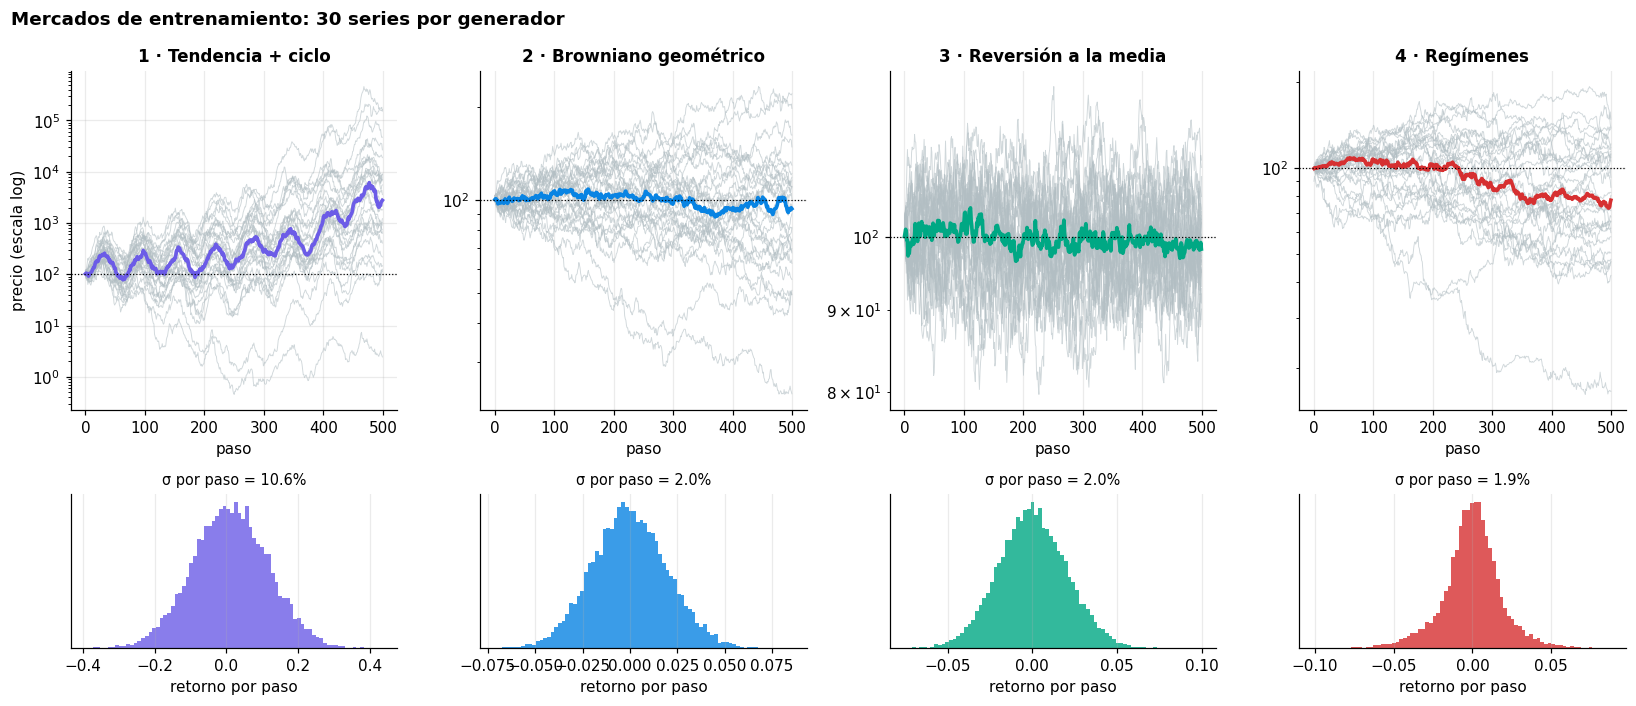

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), gridspec_kw={"height_ratios": [2.2, 1]})
for j, m in enumerate(MARKETS):
    series = np.array([make_prices(m, N_STEPS, seed) for seed in range(30)])
    ax = axes[0, j]
    ax.plot(series.T, color="#B2BEC3", lw=0.6, alpha=0.6)
    ax.plot(np.median(series, axis=0), color=MARKET_COLORS[m], lw=2.4, label="mediana")
    ax.axhline(100, color="black", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("paso")
    if j == 0: ax.set_ylabel("precio (escala log)")
    rets = np.diff(series, axis=1) / series[:, :-1]
    ax = axes[1, j]
    ax.hist(rets.ravel(), bins=80, color=MARKET_COLORS[m], alpha=0.8)
    ax.set_xlabel("retorno por paso"); ax.set_yticks([])
    ax.set_title(f"σ por paso = {rets.std():.1%}", fontsize=9.5, weight="normal")
fig.suptitle("Mercados de entrenamiento: 30 series por generador", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_mercados"); plt.show()

| Mercado | Qué lo caracteriza | Estrategia que cabe esperar *(hipótesis a comprobar en 01/02)* |
|---|---|---|
| **1 · Tendencia + ciclo** | Deriva creciente y un ciclo en los retornos (periodo ≈ 63 pasos), con **ruido enorme (σ ≈ 10 % por paso)** | Estar dentro casi siempre (deriva) y salir en la fase baja del ciclo si la tendencia lo detecta. El profesor lo consiguió batir a buy & hold |
| **2 · Browniano** | Paseo aleatorio con deriva ≈ 0 (σ = 2 %): **la tendencia no predice nada** | No hay ventaja: lo racional es operar poco. Batir a buy & hold sería suerte |
| **3 · Reversión a la media** | Oscila alrededor de 100 | Comprar tras caídas y vender tras subidas (tendencia negativa → rebote), pero el estado no ve la distancia a 100 |
| **4 · Regímenes** | Alterna tramos alcistas tranquilos y bajistas volátiles (≈ 50 pasos cada uno) | Seguir la tendencia: dentro en los alcistas y fuera en los bajistas, con el retraso de la media de 6 precios |

## 3. Un episodio de ejemplo

Es la misma figura del taller, generada con `plot_episode()` de `src/experiment.py`. Arriba, el precio con un
punto **verde** cuando el agente tiene el activo y **rojo** cuando no. Abajo, su balance frente a buy & hold.
Sirve para comprobar que el entorno de `src/` se comporta exactamente como el del enunciado.

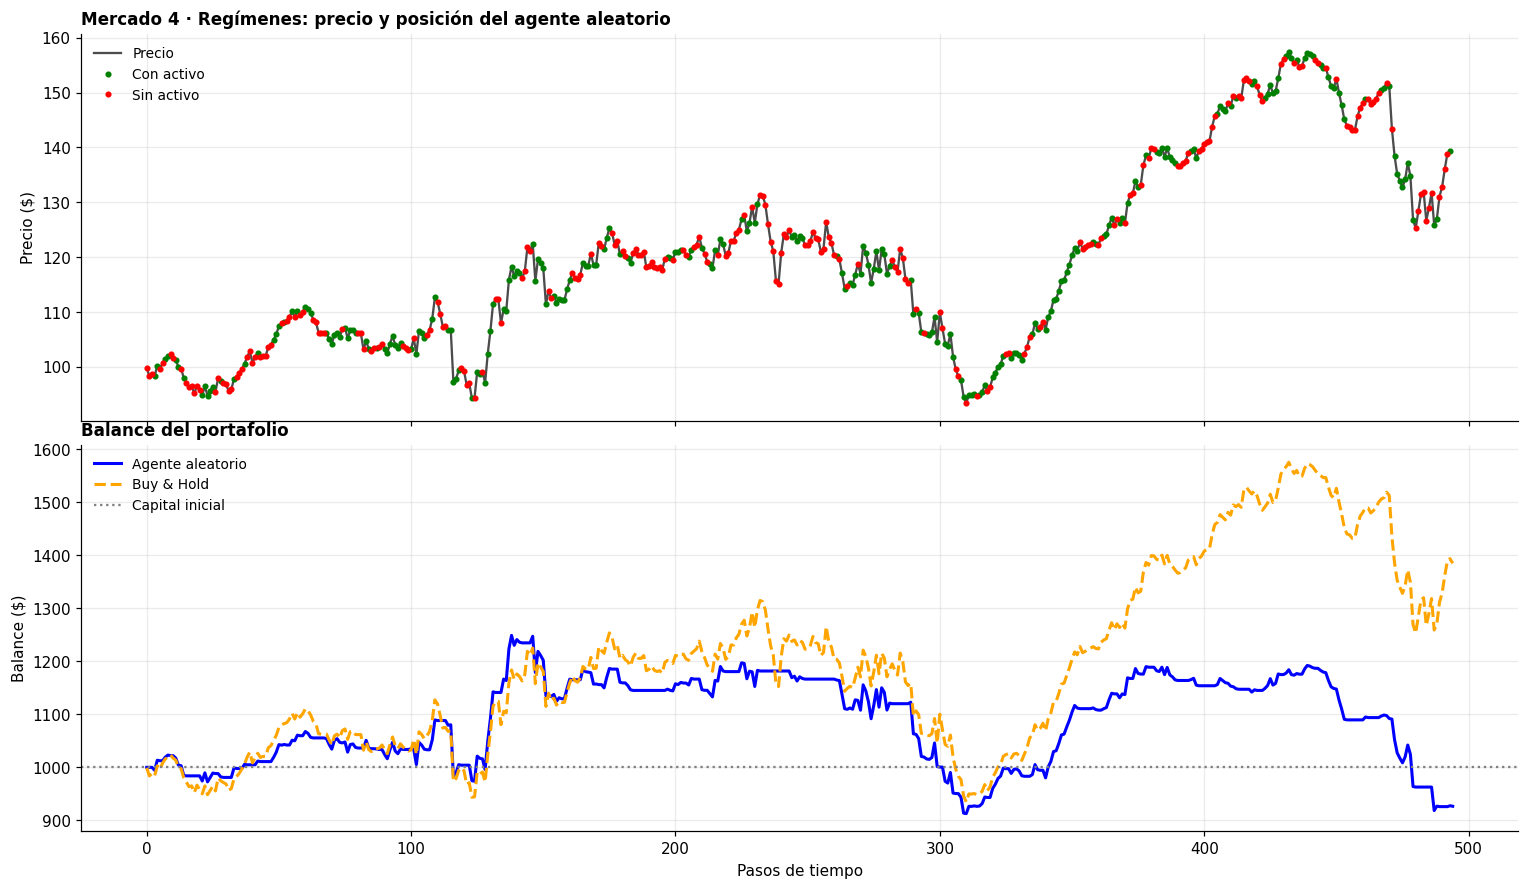

Buy & hold con BuyHoldAgent: 1,385.1017 $ · cálculo del taller: 1,385.1017 $ → coinciden


In [5]:
prices = make_prices("regimenes", N_STEPS, seed=3)
_, balances, actions, positions = run_episode(SimpleTradingEnv(prices), RandomAgent(seed=1), learn=False)
fig = plot_episode(prices, balances, positions, label="Agente aleatorio")
fig.axes[0].set_title("Mercado 4 · Regímenes: precio y posición del agente aleatorio", loc="left")
fig.axes[1].set_title("Balance del portafolio", loc="left")
savefig(fig, "00_episodio_aleatorio"); plt.show()

# Comprobación: el buy & hold del agente coincide con el cálculo del enunciado
_, bh_bal, _, _ = run_episode(SimpleTradingEnv(prices), BuyHoldAgent(), learn=False)
bh_taller = 1000 * 0.999 / prices[5] * prices[-1]
print(f"Buy & hold con BuyHoldAgent: {bh_bal[-1]:,.4f} $ · cálculo del taller: {bh_taller:,.4f} $"
      f" → {'coinciden' if np.isclose(bh_bal[-1], bh_taller) else 'NO coinciden'}")

## 4. La tendencia y su discretización

Los métodos tabulares necesitan pocos estados, así que la tendencia se parte en **bins**. La pregunta es dónde
poner los bordes. Dos opciones:

- **Fijos** (`TREND_EDGES` = ±0,005 y ±0,02): los mismos para todos los mercados.
- **Por cuantiles** (`quantile_edges(mercado, n_bins)`): calculados **solo con series de train** de ese
  mercado, para que cada bin reciba aproximadamente la misma cantidad de pasos.

Los histogramas muestran la distribución real de la tendencia con los dos juegos de bordes encima.

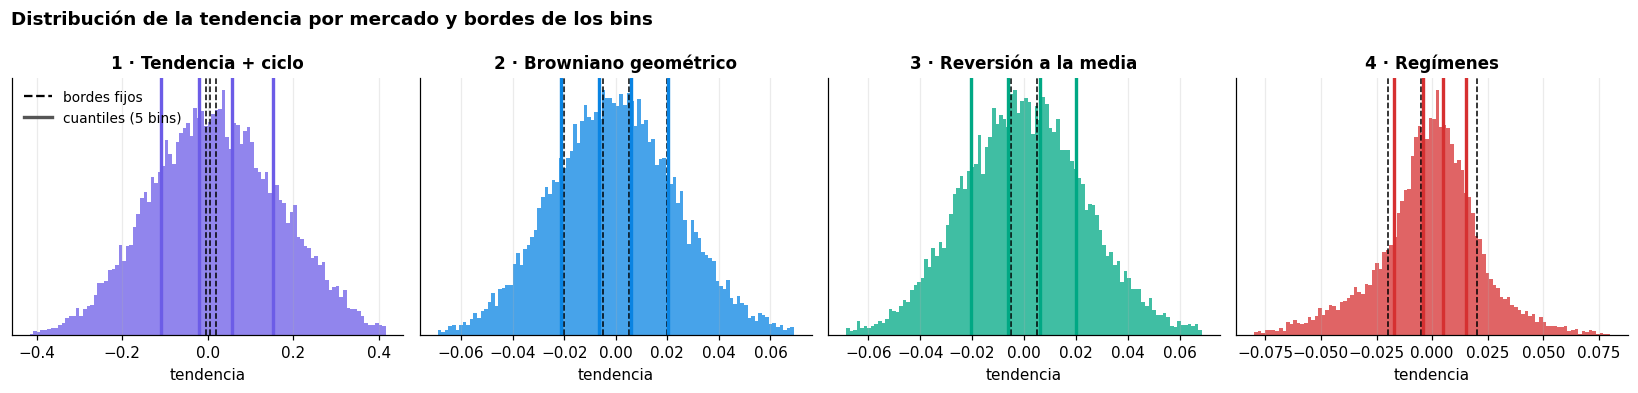

In [6]:
def trends_of(market, n_series=30, seed_offset=0):
    out = []
    for i in range(n_series):
        p = make_prices(market, N_STEPS, seed_offset + i)
        w = np.lib.stride_tricks.sliding_window_view(p, 6)
        out.append((w[:, -1] - w.mean(axis=1)) / w.mean(axis=1))
    return np.clip(np.concatenate(out), -1, 1)

EDGES_Q5 = {m: quantile_edges(m, n_bins=5) for m in MARKETS}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
ocupacion = {}
for ax, m in zip(axes, MARKETS):
    tr = trends_of(m)
    lim = np.quantile(np.abs(tr), 0.995)
    ax.hist(tr, bins=100, range=(-lim, lim), color=MARKET_COLORS[m], alpha=0.75)
    for e in TREND_EDGES: ax.axvline(e, color="black", ls="--", lw=1)
    for e in EDGES_Q5[m]: ax.axvline(e, color=MARKET_COLORS[m], lw=2.2)
    ax.set_title(MARKET_LABELS[m]); ax.set_yticks([]); ax.set_xlabel("tendencia")
    ocupacion[m] = {"fijos": np.bincount(np.digitize(tr, TREND_EDGES), minlength=5) / len(tr),
                    "cuantiles": np.bincount(np.digitize(tr, EDGES_Q5[m]), minlength=5) / len(tr)}
axes[0].plot([], [], "k--", label="bordes fijos"); axes[0].plot([], [], color="#555", lw=2.2, label="cuantiles (5 bins)")
axes[0].legend(loc="upper left")
fig.suptitle("Distribución de la tendencia por mercado y bordes de los bins", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_tendencia_bins"); plt.show()

occ = pd.DataFrame({(MARKET_LABELS[m], k): v for m, d in ocupacion.items() for k, v in d.items()},
                   index=[f"bin {i}" for i in range(5)]).T
display(occ.style.format("{:.0%}").background_gradient(cmap="Purples", vmin=0, vmax=0.6, axis=None)
        .set_caption("Fracción de pasos que cae en cada bin (5 bins)"))

**Lectura:** en los mercados 2, 3 y 4 los bordes fijos y los cuantiles casi coinciden. En el **mercado 1**, con
ruido del 10 % por paso, la tendencia es diez veces más ancha: con bordes fijos **casi todos los pasos caen en los
dos bins extremos** y el agente se queda prácticamente sin información. Por eso usamos **bordes por cuantiles de
cada mercado** (D-1.1, opción b). En el §7 se decide cuántos bins.

## 5. Protocolo de train/test (D-0.1)

| | Semillas | Uso |
|---|---|---|
| **Entrenamiento** | `0, 1, 2, …` (una serie nueva en cada episodio) | `train(agent, mercado, n_episodios)` |
| **Bins** | las 50 primeras de train | `quantile_edges(mercado, N_BINS)` |
| **Test** | `100 000, 100 001, …` (`N_TEST` series) | `evaluate(agent, mercado)`: política greedy, sin aprender |

Con 100 000 de separación, train y test no comparten nunca una serie (haría falta entrenar 100 000 episodios). Falta
fijar **cuántas series de test** bastan: el gráfico muestra cómo se estabiliza la mediana del retorno de buy & hold
al añadir series, con una banda de ±1 error estándar.

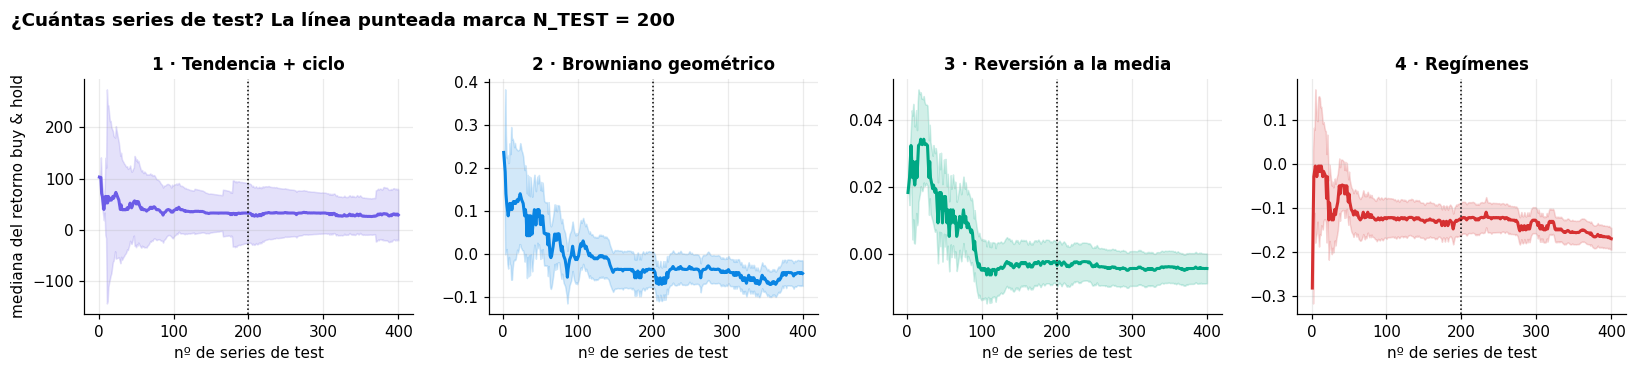

,mediana con 200,mediana con 400,EE con 200
mercado,,,
1 · Tendencia + ciclo,+3261.7%,+2891.5%,+5818.0%
2 · Browniano geométrico,-3.5%,-4.4%,+4.1%
3 · Reversión a la media,-0.3%,-0.4%,+0.6%
4 · Regímenes,-12.5%,-17.0%,+3.6%


In [7]:
N_MAX = 400
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
filas = []
for ax, m in zip(axes, MARKETS):
    r = evaluate(BuyHoldAgent(), m, n_test=N_MAX)["retorno"].to_numpy()
    k = np.arange(1, N_MAX + 1)
    med = np.array([np.median(r[:i]) for i in k])
    se = np.array([1.2533 * r[:i].std(ddof=1) / np.sqrt(i) if i > 1 else np.nan for i in k])  # EE de la mediana
    ax.plot(k, med, color=MARKET_COLORS[m], lw=2)
    ax.fill_between(k, med - se, med + se, color=MARKET_COLORS[m], alpha=0.18)
    ax.axvline(N_TEST, color="black", ls=":", lw=1)
    ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("nº de series de test")
    filas.append({"mercado": MARKET_LABELS[m], f"mediana con {N_TEST}": med[N_TEST - 1],
                  f"mediana con {N_MAX}": med[-1], f"EE con {N_TEST}": se[N_TEST - 1]})
axes[0].set_ylabel("mediana del retorno buy & hold")
fig.suptitle(f"¿Cuántas series de test? La línea punteada marca N_TEST = {N_TEST}", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_n_test"); plt.show()
display(pd.DataFrame(filas).set_index("mercado").style.format("{:+.1%}"))

## 6. Baselines: aleatorio y buy & hold

Es el **listón a batir** por Q-Learning y SARSA, medido con el mismo protocolo que usarán ellos. Como métrica
principal se usa la **mediana del retorno**, porque en el mercado 1 la media la distorsionan unos pocos valores
enormes (D-0.3). La media ± std se guarda al lado.

In [8]:
baselines, dist = [], {}
for m in MARKETS:
    for name, ag in [("aleatorio", RandomAgent(seed=0)), ("buy_hold", BuyHoldAgent())]:
        df = evaluate(ag, m)
        baselines.append(summarize(name, m, df))
        dist[(m, name)] = df["retorno"].to_numpy()
res00 = save_results(baselines, "00_baselines")

vista = (res00.assign(mercado=res00["mercado"].map(MARKET_LABELS))
         .set_index(["mercado", "agente"])[["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades"]])
display(vista.style.format({"retorno_mediana": "{:+.1%}", "retorno_medio": "{:+.1%}", "std": "{:.1%}",
                            "sharpe": "{:+.3f}", "max_drawdown": "{:.1%}", "n_trades": "{:.0f}"})
        .background_gradient(subset=["retorno_mediana"], cmap="RdYlGn", vmin=-0.3, vmax=0.3)
        .set_caption(f"Baselines en {N_TEST} series de test · guardado en results/00_baselines.csv"))

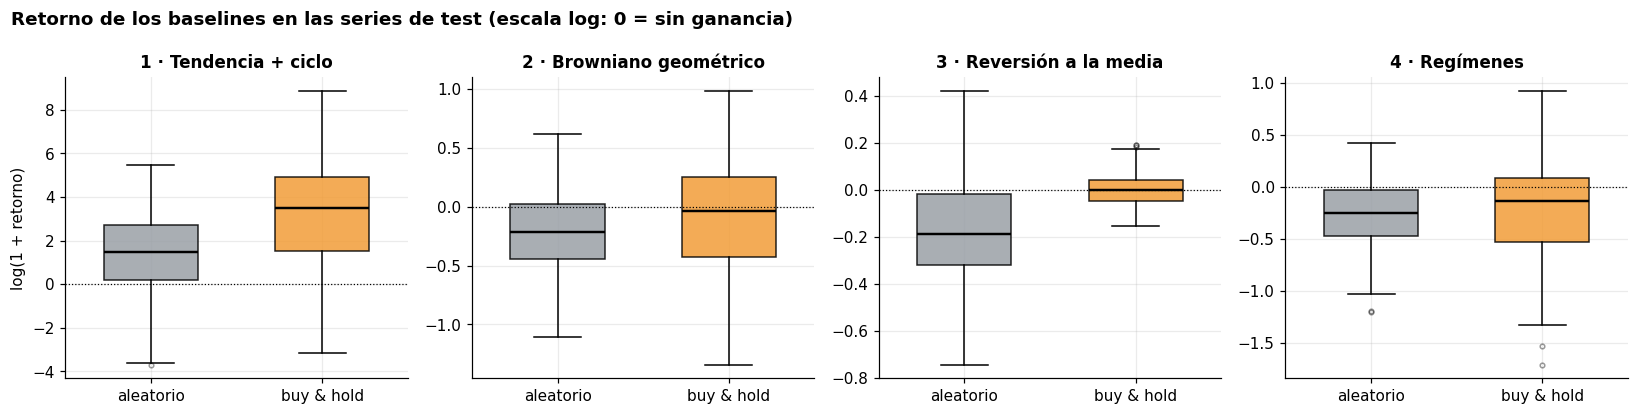

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, MARKETS):
    data = [np.log1p(dist[(m, a)]) for a in ("aleatorio", "buy_hold")]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=True,
                    medianprops=dict(color="black", lw=1.6), flierprops=dict(marker=".", alpha=0.4))
    for patch, a in zip(bp["boxes"], ("aleatorio", "buy_hold")):
        patch.set_facecolor(AGENT_COLORS[a]); patch.set_alpha(0.85)
    ax.axhline(0, color="black", ls=":", lw=0.8)
    ax.set_xticks([1, 2], ["aleatorio", "buy & hold"]); ax.set_title(MARKET_LABELS[m])
axes[0].set_ylabel("log(1 + retorno)")
fig.suptitle("Retorno de los baselines en las series de test (escala log: 0 = sin ganancia)", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_baselines"); plt.show()

## 7. Calibración con un Q-Learning rápido

Para decidir cuántos bins hay que ver cómo aprende un agente con cada opción. Para eso se usa un **Q-Learning de
calibración**, que es la regla de slides3 p36 tal cual.

> ⚠️ `QCalibracion` es una herramienta **solo para este notebook**. La implementación oficial
> (`QLearningAgent.update` en `src/agents.py`), el ajuste fino de hiperparámetros y el análisis son el trabajo del
> **01**. Aquí no se busca el mejor agente, sino comparar opciones en igualdad de condiciones.

In [10]:
class QCalibracion(QLearningAgent):
    """Q-Learning (slides3 p36) solo para calibrar. La versión oficial va en src/agents.py (01)."""
    def update(self, s, a, r, s2, a2, done):
        target = r if done else r + self.gamma * self.Q[s2].max()
        self.Q[s, a] += self.alpha * (target - self.Q[s, a])

N_EP = 500

def run_config(market, edges, alpha, gamma=0.9, name=""):
    ag = QCalibracion(edges=edges, alpha=alpha, gamma=gamma, epsilon_decay=0.99, seed=0)
    rewards, t = train(ag, market, N_EP)
    return summarize(name, market, evaluate(ag, market), rewards, t), rewards, ag

def ret_formatter(ax, values):
    """Ejes en % salvo que haya retornos enormes (mercado 1): entonces en múltiplos del capital."""
    if np.nanmax(np.abs(values)) > 5:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"x{1 + v:,.0f}"))
    else:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))

def bars_vs_baselines(ax, m, labels, values, trades, colors):
    x = np.arange(len(labels))
    ax.bar(x, values, color=colors, width=0.65)
    for xi, v, n in zip(x, values, trades):
        if n == 0 and v == 0:   # no opera: barra de altura 0, se marca para que se vea
            ax.plot(xi, 0, marker="D", ms=9, color=colors[xi], mec="black", mew=0.8, zorder=5)
            ax.annotate("0 %" + chr(10) + "no opera", (xi, 0), xytext=(0, -26), textcoords="offset points",
                        ha="center", fontsize=8.5, weight="bold", color="#333")
        else:
            ax.annotate(f"{n:.0f} ops", (xi, v), xytext=(0, 3 if v > 0 else -12), textcoords="offset points",
                        ha="center", fontsize=8, color="#333")
    refs = []
    for nombre, ls, lab in [("buy_hold", "--", "buy & hold"), ("aleatorio", ":", "aleatorio")]:
        v = res00[(res00.mercado == m) & (res00.agente == nombre)]["retorno_mediana"].iloc[0]
        ax.axhline(v, color=AGENT_COLORS[nombre], ls=ls, lw=2, label=lab); refs.append(v)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x, labels, rotation=15); ax.set_title(MARKET_LABELS[m]); ax.margins(y=0.15)
    ret_formatter(ax, np.concatenate([values, refs]))
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, max(hi, 0.07 * (hi - lo)))   # deja aire sobre el 0 para el rombo

### 7.1 Primero, la tasa de aprendizaje α

Con los 10 bins por cuantiles (`N_BINS`, D-1.1), γ = 0,9 y ε de 1 a 0,01 (decaimiento 0,99 por episodio), se prueban tres valores de α.
Encima de cada barra se indica el número medio de operaciones por episodio de test. Un rombo en el 0 % marca un
agente que **no opera nunca**: su barra mide cero, por eso no se ve.

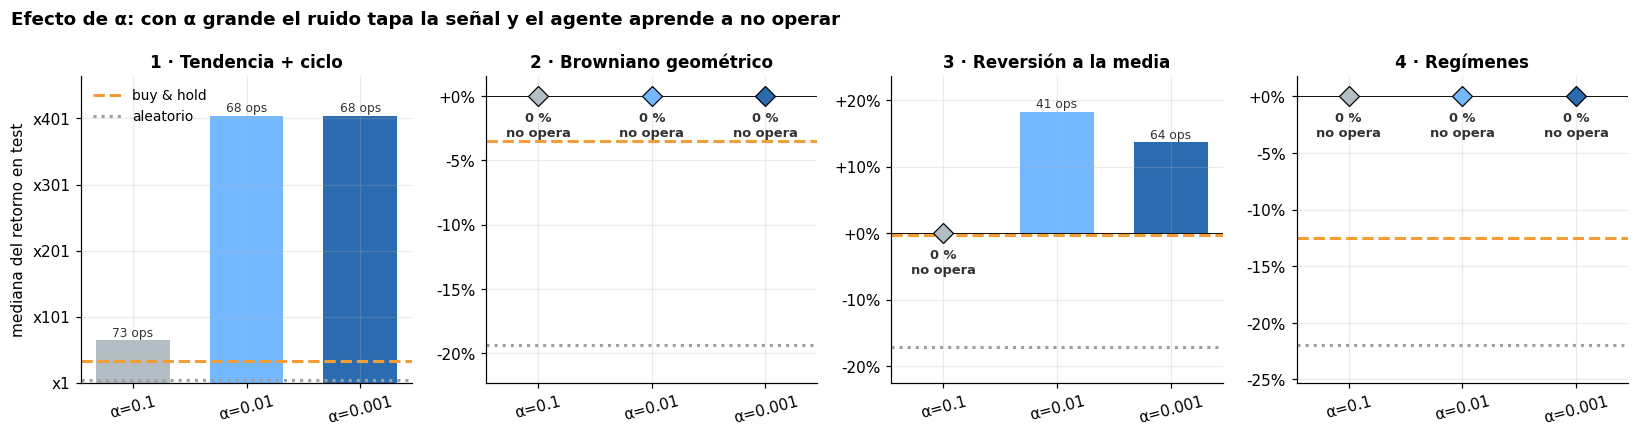

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
agente,,,,
α=0.1,+6399.9%,+0.0%,+0.0%,+0.0%
α=0.01,+40352.0%,+0.0%,+18.3%,+0.0%
α=0.001,+40352.0%,+0.0%,+13.6%,+0.0%


In [11]:
ALPHAS = [0.1, 0.01, 0.001]
ALPHA_COLORS = ["#B2BEC3", "#74B9FF", "#2B6CB0"]
res_alpha = []
for m in MARKETS:
    edges = quantile_edges(m, n_bins=N_BINS)
    for al in ALPHAS:
        res_alpha.append(run_config(m, edges, al, name=f"α={al}")[0])
res_alpha = pd.DataFrame(res_alpha)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, m in zip(axes, MARKETS):
    sub = res_alpha[res_alpha.mercado == m]
    bars_vs_baselines(ax, m, sub.agente, sub.retorno_mediana.to_numpy(), sub.n_trades.to_numpy(), ALPHA_COLORS)
axes[0].set_ylabel("mediana del retorno en test"); axes[0].legend(loc="best")
fig.suptitle("Efecto de α: con α grande el ruido tapa la señal y el agente aprende a no operar",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_calibracion_alpha"); plt.show()

tabla_alpha = (res_alpha.assign(mercado=res_alpha["mercado"].map(MARKET_LABELS))
               .pivot(index="agente", columns="mercado", values="retorno_mediana").loc[[f"α={a}" for a in ALPHAS]])
display(tabla_alpha.style.format("{:+.1%}").background_gradient(cmap="RdYlGn", axis=0)
        .set_caption("Mediana del retorno en test según α (10 bins por cuantiles)"))

**Por qué pasa.** Con un α constante, Q es una media móvil exponencial de los objetivos. Su ruido es
$\approx \sigma\sqrt{\alpha/2}$: con σ = 2 % por paso y α = 0,1 da ≈ 0,45 %, mientras que la ventaja real que aporta
la tendencia es del orden de **0,1 % por paso**. El ruido tapa la señal, alguna mala racha deja *comprar* por
debajo de *no hacer nada* (cuyo valor es 0) y el agente deja de entrar en el mercado. Con α pequeño la estimación
promedia muchos más pasos y la señal aparece. Con 10 bins, α = 0,01 ya basta en reversión (+18,3 %), mientras que α = 0,1 no aprende en ningún mercado salvo el 1.
**Para el 01 y el 02: α tiene que estar entre 10⁻³ y 10⁻² (o ser decreciente), nunca en 0,1.**

### 7.2 Después, la discretización

Con α = 0,001 se comparan tres opciones de bins:

| Opción | Bins | Estados |
|---|---|---|
| `fijos-5` | 5, bordes fijos | 10 |
| `cuantiles-5` | 5 por cuantiles del mercado | 10 |
| `cuantiles-10` | 10 por cuantiles del mercado (**recomendación del profesor**, opción elegida) | 20 |

Si las tres rinden igual, nos quedamos con 10, que es lo que recomendó el profesor en clase (~04:27).

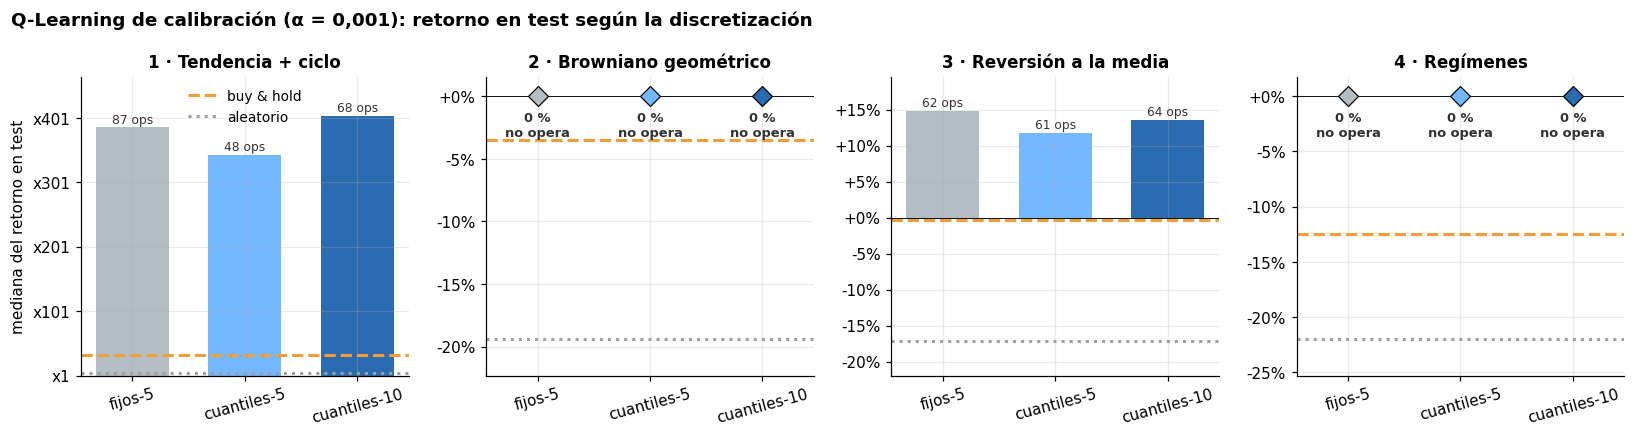

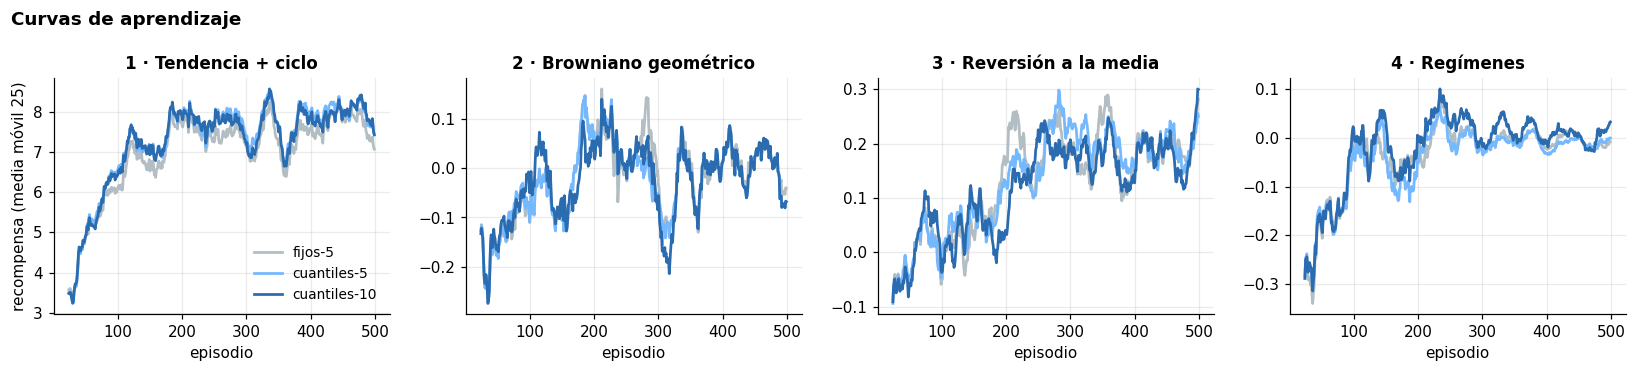

In [12]:
OPCIONES = {"fijos-5": lambda m: TREND_EDGES,
            "cuantiles-5": lambda m: quantile_edges(m, n_bins=5),
            "cuantiles-10": lambda m: quantile_edges(m, n_bins=10)}
OPC_COLORS = ["#B2BEC3", "#74B9FF", "#2B6CB0"]
calib, curvas, agentes = [], {}, {}
for m in MARKETS:
    for opcion, edges_fn in OPCIONES.items():
        fila, rewards, ag = run_config(m, edges_fn(m), alpha=0.001, name=opcion)
        calib.append(fila); curvas[(m, opcion)] = rewards; agentes[(m, opcion)] = ag
calib = pd.DataFrame(calib)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, m in zip(axes, MARKETS):
    sub = calib[calib.mercado == m]
    bars_vs_baselines(ax, m, sub.agente, sub.retorno_mediana.to_numpy(), sub.n_trades.to_numpy(), OPC_COLORS)
axes[0].set_ylabel("mediana del retorno en test"); axes[0].legend(loc="best")
fig.suptitle("Q-Learning de calibración (α = 0,001): retorno en test según la discretización", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_calibracion_bins"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, m in zip(axes, MARKETS):
    for o, c in zip(OPCIONES, OPC_COLORS):
        ax.plot(pd.Series(curvas[(m, o)]).rolling(25).mean(), color=c, lw=1.8, label=o)
    ax.set_title(MARKET_LABELS[m]); ax.set_xlabel("episodio")
axes[0].set_ylabel("recompensa (media móvil 25)"); axes[0].legend()
fig.suptitle("Curvas de aprendizaje", x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_calibracion_curvas"); plt.show()

In [13]:
tabla_cal = (calib.assign(mercado=calib["mercado"].map(MARKET_LABELS))
             .pivot(index="agente", columns="mercado", values="retorno_mediana").loc[list(OPCIONES)])
bh = res00[res00.agente == "buy_hold"].assign(mercado=lambda d: d.mercado.map(MARKET_LABELS)).set_index("mercado")["retorno_mediana"]
tabla_cal.loc["buy & hold (ref.)"] = bh[tabla_cal.columns]
display(tabla_cal.style.format("{:+.1%}").background_gradient(cmap="RdYlGn", axis=0)
        .set_caption("Mediana del retorno en test (α = 0,001) frente a buy & hold"))

mercado,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
agente,,,,
fijos-5,+38527.2%,+0.0%,+14.8%,+0.0%
cuantiles-5,+34200.9%,+0.0%,+11.8%,+0.0%
cuantiles-10,+40352.0%,+0.0%,+13.6%,+0.0%
buy & hold (ref.),+3261.7%,-3.5%,-0.3%,-12.5%


### 7.3 ¿Qué ha aprendido? La política greedy

Para cada bin de tendencia (columnas, de más bajista a más alcista) y cada posición (filas), la acción que elige el
agente de `cuantiles-10`. Es la forma más directa de comprobar si la estrategia es la esperada (§2).

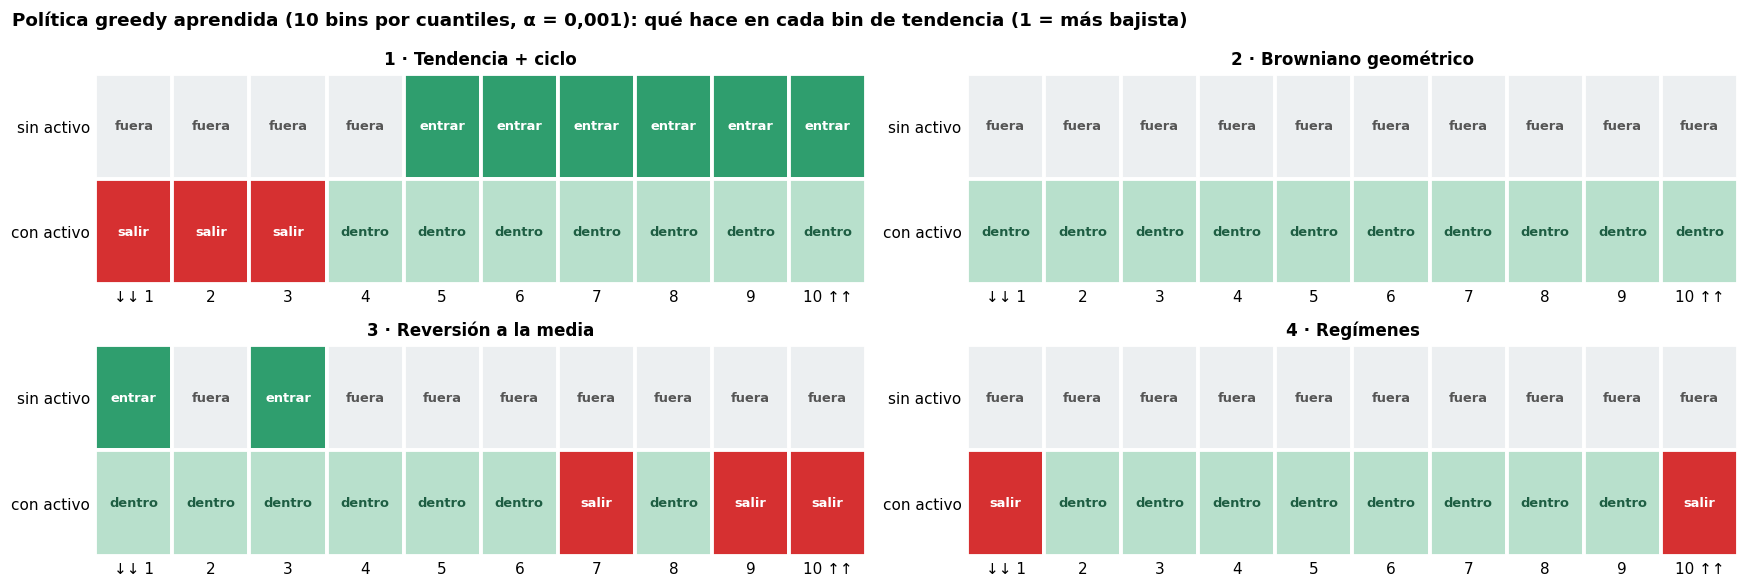

In [14]:
# Acción efectiva: sin activo, "comprar" = entrar y lo demás = quedarse fuera;
# con activo, "vender" = salir y lo demás = seguir dentro
EFECTO = {(0, True): ("entrar", "#2F9E6E", "white"), (0, False): ("fuera", "#ECEFF1", "#555"),
          (1, True): ("salir", "#D63031", "white"), (1, False): ("dentro", "#B8E0CC", "#1E5E43")}
fig, axes = plt.subplots(2, 2, figsize=(16, 5.4))
for ax, m in zip(axes.ravel(), MARKETS):
    pol = agentes[(m, "cuantiles-10")].Q.reshape(-1, 2, 3).argmax(axis=2)   # [bin, posición]
    for b_ in range(pol.shape[0]):
        for pos in (0, 1):
            opera = pol[b_, pos] == (2 if pos == 0 else 0)
            txt, fc, tc = EFECTO[(pos, opera)]
            ax.add_patch(plt.Rectangle((b_, 1 - pos), 1, 1, fc=fc, ec="white", lw=2.5))
            ax.text(b_ + 0.5, 1.5 - pos, txt, ha="center", va="center", fontsize=8.5, color=tc, weight="bold")
    ax.set_xlim(0, pol.shape[0]); ax.set_ylim(0, 2); ax.grid(False)
    nb_ = pol.shape[0]
    ax.set_xticks(np.arange(nb_) + 0.5, ["↓↓ 1"] + [str(i) for i in range(2, nb_)] + [f"{nb_} ↑↑"])
    ax.set_yticks([0.5, 1.5], ["con activo", "sin activo"]); ax.set_title(MARKET_LABELS[m])
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
fig.suptitle("Política greedy aprendida (10 bins por cuantiles, α = 0,001): qué hace en cada bin de tendencia (1 = más bajista)",
             x=0.01, ha="left", weight="bold")
fig.tight_layout(); savefig(fig, "00_politica_calibracion"); plt.show()

## 8. Decisiones cerradas y cómo seguir

### Lo que hemos aprendido

| # | Hallazgo | Evidencia |
|---|---|---|
| 1 | El entorno de `src/` reproduce exactamente el del taller | §3: el buy & hold coincide al céntimo |
| 2 | **Con 50 series de test no basta**: la mediana de buy & hold se mueve hasta 10 puntos (browniano: +6,9 % con 50, −3,5 % con 200) | §5 |
| 3 | El **aleatorio pierde frente a buy & hold en los 4 mercados**: unas 165 operaciones por episodio a un 0,1 % de comisión cada una | §6 |
| 4 | El listón (mediana de buy & hold) es **x33 · −3,5 % · −0,3 % · −12,5 %**. En los mercados 2, 3 y 4, **no operar (0 %) ya lo iguala o lo bate** | §6 |
| 5 | **Con α = 0,1 el agente no aprende en los mercados 2–4**, porque el ruido de Q (≈ σ√(α/2) ≈ 0,45 %) tapa una ventaja de ≈ 0,1 % por paso. Con α = 0,01 o 0,001 sí aprende: en reversión, +18,3 % y +13,6 % | §7.1 |
| 6 | Las tres discretizaciones dan **resultados equivalentes** (en reversión, entre +11,8 % y +14,8 %), dentro del ruido de un solo entrenamiento. Se eligen **10 bins, como recomendó el profesor** | §7.2 |
| 7 | **La política aprendida es la esperada en 3 de los 4 mercados**: seguir la tendencia en el 1 (entra en los bins 5–10 y sale en los 1–3), no operar en el 2 y comprar tras las caídas y vender en las subidas en el 3. En el 4 se queda siempre fuera: bate a buy & hold (0 % frente a −12,5 %), pero **no encuentra el seguimiento de tendencia** que cabía esperar | §7.3 |

### Decisiones

| ID | Decisión | Motivo |
|---|---|---|
| **D-0.1** ✅ | Series de 500 pasos; train con semillas `0, 1, …`; **`N_TEST = 200`** series de test desde la semilla 100 000, con política greedy | Hallazgo 2: con 200, el error estándar de la mediana baja a ≈ ±4 puntos (±0,6 en reversión) |
| **D-1.1** ✅ | **Bins por cuantiles de cada mercado, `N_BINS = 10`** (20 estados): `quantile_edges(m, N_BINS)` | Recomendación del profesor ("partís en 10 cachitos", ~04:27), con un rendimiento igual o mejor que 5 (hallazgo 6). Los cuantiles se adaptan solos a la escala de cada mercado; los bordes fijos saturan en el mercado 1 (§4) |
| **D-0.3** ✅ | Métrica principal: **mediana del retorno**, con la media ± std al lado | En el mercado 1 la media de buy & hold es +19 925 % y la mediana +3 262 % |
| **D-2.2** | α entre 10⁻² y 10⁻³ como punto de partida del ajuste; nunca 0,1 | Hallazgo 5 |

### Pistas para el 01 y el 02

- **α es el hiperparámetro crítico** (hallazgo 5): hay que barrerlo primero entre 10⁻³ y 10⁻², o probar un α decreciente.
- **El reto es el mercado 4**: ¿aprende a seguir la tendencia con más episodios u otro γ? La media de 6 precios reacciona
  con retraso frente a regímenes de unos 50 pasos.
- **Comparad siempre contra la referencia correcta**: en 2–4, "no operar" ya bate o iguala a buy & hold. Un agente que
  no opera no ha aprendido nada interesante, aunque gane.
- Aquí se ha entrenado con **una sola semilla**. Para las conclusiones finales conviene promediar varias semillas
  de entrenamiento.

### Plantilla para empezar el 01, el 02 o el 03

```python
from src.experiment import train, evaluate, summarize, save_results, quantile_edges, N_BINS

filas = []
for m in MARKETS:
    agent = QLearningAgent(edges=quantile_edges(m, n_bins=N_BINS), alpha=..., gamma=..., epsilon_decay=..., seed=0)
    rewards, t = train(agent, m, n_episodes=...)
    filas.append(summarize("qlearning", m, evaluate(agent, m), rewards, t))
save_results(filas, "01_qlearning")   # → results/01_qlearning.csv, con el mismo esquema que 00_baselines.csv
```

Las figuras para el informe se guardan con `savefig(fig, "01_nombre")` en `results/figures/`, y cualquier cambio en
`src/` se avisa al grupo y se anota en `docs/DECISIONES.md`.